# Generic E-commerce Scraper → Data Mining → Backend

Works on **any** e-commerce site: site-specific knowledge (URL, CSS
selectors, field extractors, backend mapping) lives in **one declaration
cell**. Swap `ACTIVE_SITE` to scrape a different shop — no other cell
needs to change.

```
Declaration cell (site profile + mining config)
        ↓
Scrape (generic, profile-driven)  →  RawProduct records
        ↓
Detail stage (follow each product's link / slug)  →  full description,
specs table, gallery images, rating for every product
        ↓
Data mining (clean → engineer → EDA → models)   ← config-driven
        ↓
Enrich records with mined values (price imputation, features, segments)
        ↓
CSV export (mined dataset saved locally, path in the declaration)
        ↓
POST to backend (skip-if-exists, throttled, retried)
```

## Cell 0 — Declaration (the only cell you edit per site)

`SITE_PROFILES` maps a site name to everything that differs between
shops; `GENERIC_DERIVE` / `BRAND_HINTS` hold the product-agnostic feature
patterns (the same vague patterns on every site), `TARGETS` declares what
the models predict and classify, and `MINING_CONFIG` decides how the mined
data is built. Adding a new site = adding a profile entry + setting
`ACTIVE_SITE`.

Each profile may also declare a `detail` block: selectors for the product's
**own page**, fetched after the listing stage by following the `url` that was
collected per card (the same slug the backend dedupes on).

In [17]:
# ============================================================
# DECLARATION — edit this cell to support a new site / schema
# ============================================================

BACKEND_URL = "http://localhost:8001"
API_PREFIX = "/api/v1"
PRODUCT_ENDPOINT = f"{BACKEND_URL}{API_PREFIX}/product"

ACTIVE_SITE = "startech"           # <- switch sites here

# ===========================================================================
# GENERIC, SITE-AGNOSTIC DECLARATIONS — identical for every shop / product
# ===========================================================================

# --- vague feature-derivation patterns -------------------------------------
# Applied to EVERY site's product text (name + description). The patterns
# are deliberately broad so they work for anything product related (ACs,
# TVs, phones, fridges, ...); a pattern that never matches simply leaves
# the feature NaN (numeric) or False (flag) instead of breaking anything.
GENERIC_DERIVE = {
    # numeric attributes: "<number> <unit>" found anywhere in the text
    "size":     {"pattern": r'(\d+(?:\.\d+)?)\s*(?:inch(?:es)?|cms?|mms?|fts?|")', "as": "float"},
    "capacity": {"pattern": r"(\d+(?:\.\d+)?)\s*(?:tons?|btus?|cc|ml|ltrs?|litres?|liters?|kg)\b", "as": "float"},
    "power":    {"pattern": r"(\d+(?:\.\d+)?)\s*(?:kw|watts?|w|hp)\b", "as": "float"},
    "storage":  {"pattern": r"(\d+(?:\.\d+)?)\s*(?:gb|tb)\b", "as": "float"},
    "battery":  {"pattern": r"(\d+(?:\.\d+)?)\s*(?:mah|ah)\b", "as": "float"},

    # boolean flags: presence anywhere in the text (False when absent)
    "is_smart":        {"pattern": r"\bsmart\b"},
    "is_wireless":     {"pattern": r"(wi-?fi|wireless|bluetooth)"},
    "is_inverter":     {"pattern": r"\binverter\b", "negative": r"non-?\s*inverter"},
    "is_hd":           {"pattern": r"(4k|uhd|fhd|full hd|1080p|\bhd\b)"},
    "is_rechargeable": {"pattern": r"recharge"},
    "is_refurbished":  {"pattern": r"(refurbished|refurb|renewed|open[- ]box)"},
    "is_bundle":       {"pattern": r"(bundle|combo|pack of|set of)"},
}

# --- one broad brand list for every site -----------------------------------
# Brand detection is a word-list match against the product name: a single
# shared list instead of a per-site one, so any shop's catalogue resolves
# to sensible brand labels.
BRAND_HINTS = [
    # home appliances / AC / kitchen
    "gree", "haier", "midea", "daikin", "panasonic", "sharp", "singer",
    "walton", "vision", "crest", "beko", "bosch", "siemens", "whirlpool",
    "hitachi", "kenwood", "philips", "hisense", "tcl", "lg", "samsung",
    "sony",
    # phones / computing
    "xiaomi", "realme", "oppo", "vivo", "oneplus", "motorola", "nokia",
    "huawei", "apple", "google", "microsoft", "dell", "hp", "lenovo",
    "asus", "acer", "msi",
    # audio / misc brands seen on BD shops
    "bristor", "ecstar", "syphons", "mitashi", "jbl", "bose", "logitech",
]

# --- what the mining stage predicts / classifies ---------------------------
# Declare the modelling targets here; every modelling cell reads this and
# nothing else — change a value and re-run from the cleaning cell onward.
#   regression     : numeric column to predict. "price" by default,
#                    "auto" -> first numeric column, None -> skipped.
#   classification : column to classify. "auto" -> first derived boolean
#                    flag that shows two classes in the data, None -> skipped.
TARGETS = {
    "regression": "price",
    "classification": "auto",
}


def resolve_targets(frame):
    """Turn the declared TARGETS into column names this dataset can use.

    Returns (regression_target, classification_target); either is None
    when the declared target is disabled or unusable for this frame.
    """
    reg = TARGETS.get("regression")
    clf = TARGETS.get("classification")

    # regression: a numeric column; "auto" prefers price, else any numeric
    if isinstance(reg, str) and reg.strip().lower() == "auto":
        numeric = [c for c in frame.columns if pd.api.types.is_numeric_dtype(frame[c])]
        reg = "price" if "price" in numeric else (numeric[0] if numeric else None)
    if not isinstance(reg, str) or reg not in frame.columns \
            or not pd.api.types.is_numeric_dtype(frame[reg]):
        reg = None

    # classification: any column; "auto" = first derived *boolean flag*
    # that shows two classes in this dataset (numeric derive features are
    # regression material, never classification targets)
    if isinstance(clf, str) and clf.strip().lower() == "auto":
        clf = next(
            (f for f, s in (SITE.get("derive") or {}).items()
             if s.get("as") != "float"
             and f in frame.columns
             and frame[f].dropna().nunique() >= 2),
            None,
        )
    elif isinstance(clf, str) and (clf not in frame.columns or frame[clf].dropna().empty):
        clf = None

    return reg, clf


SITE_PROFILES = {
    "startech": {

        # --- what to scrape ---
        "name": "startech",
        "list_urls": [
            "https://www.startech.com.bd/server-networking",
        ],
        "max_pages": 3,
        "pagination_param": "page",

        # --- where the data lives in the listing card ---
        "item_selector": ".p-item",
        "fields": {
            "name":        {"selector": ".p-item-name a", "attr": "text"},
            "url":         {"selector": ".p-item-name a", "attr": "href"},
            "price":       {"selector": "meta[itemprop='price']", "attr": "content"},
            "image":       {"selector": "img[itemprop='image']", "attr": "src"},
            "availability": {"selector": "meta[itemprop='availability']", "attr": "content"},
        },
        "spec_selectors": {          # optional key: value lists inside the card
            "specifications": ".short-description li",
        },
        "external_id_pattern": r"cart\.add\(['\"]([^'\"]+)",   # searched in onclick attrs

        # --- detail page: the product's own page, reached via the url/slug
        #     collected from the listing card (fetched after the listing stage) ---
        "detail": {
            "enabled": True,
            "concurrency": 4,   # parallel detail fetches (shared limiter still applies)
            "fields": {
                "name":              {"selector": "h1.product-name", "attr": "text"},
                "price":             {"selector": "meta[itemprop='price']", "attr": "content"},
                "availability":      {"selector": "link[itemprop='availability']", "attr": "href"},
                "description":       {"selector": ".full-description", "attr": "text", "separator": " "},
                "short_description": {"selector": ".short-description", "attr": "text", "separator": " "},
                "rating":            {"selector": ".average-rating", "attr": "text", "regex": r"(\d+(?:\.\d+)?)"},
                "rating_count":      {"selector": "section#write-review h2", "attr": "text", "regex": r"\((\d+)\)"},
            },
            # key/value <tr> tables on the detail page -> merged into specifications
            "spec_tables": {
                "specifications": "section#specification table.data-table tr",
            },
            # gallery images -> merged into the payload's images list
            "gallery": {"selector": ".product-images img", "attr": "src"},
        },

        # --- how raw values are cleaned into canonical types ---
        "normalizers": {
            "price": "bdt_price",          # 'Tk 41,000' / '41000' -> float
            "availability": "schema_org",  # 'https://schema.org/InStock' -> 'InStock'
        },

        # (features/brands come from the generic block above — GENERIC_DERIVE/BRAND_HINTS)
    },

    # ---- second site, proving the config-driven design ----
    "techland": {
        "name": "techland",
        "list_urls": [
            "https://www.techlandbd.com/",
        ],
        "max_pages": 2,
        "pagination_param": "page",
        "item_selector": "div.product-layout",
        "fields": {
            "name":   {"selector": "h4 a", "attr": "text"},
            "url":    {"selector": "h4 a", "attr": "href"},
            "price":  {"selector": ".price", "attr": "text"},
            "image":  {"selector": "img", "attr": "src"},
        },
        "spec_selectors": {},
        "external_id_pattern": None,

        # NOTE: techland's detail selectors are best-effort guesses — the site
        # answers 403 to scripted requests, so verify them on the first real run.
        "detail": {
            "enabled": True,
            "concurrency": 3,
            "fields": {
                "description": {"selector": "#tab-description", "attr": "text", "separator": " "},
            },
            "spec_tables": {
                "specifications": "table.attribute tr",
            },
            "gallery": {
                "selector": ".product-images img, .additional-images img, .thumbnail img",
                "attr": "src",
            },
        },

        "normalizers": {"price": "bdt_price"},
        # (features/brands come from the generic block above — GENERIC_DERIVE/BRAND_HINTS)
    },

    # ---- third site: a Next.js shop whose listing cards are rendered by
    # client-side React (card markup is near-empty skeletons). The real data
    # ships inside <script id="__NEXT_DATA__" type="application/json">, so
    # this profile uses the generic `json_extract` channel; the CSS selectors
    # stay as a fallback + merge source (name/url matching joins the two).
    "pickaboo": {
        "name": "pickaboo",
        "list_urls": [
            "https://www.pickaboo.com/product/television",
        ],
        "max_pages": 4,
        "pagination_param": "page",

        # --- CSS fallback cards (fewer fields than the JSON channel) ---
        "item_selector": "div.product-one",
        "fields": {
            "name":         {"selector": ".product-title", "attr": "text"},
            "url":          {"selector": "a[href*='/product-detail/']", "attr": "href"},
            "price":        {"selector": ".product-price", "attr": "text",
                             "regex": r"(\d[\d,]*(?:\.\d+)?)"},
            "rating_count": {"selector": ".stars-rating", "attr": "text",
                             "regex": r"\((\d+)\)"},
        },
        "spec_selectors": {},
        "external_id_pattern": None,

        # --- JSON-in-HTML extraction (runs after the CSS pass, then merges
        #     into the matched cards; unmatched JSON items become records too) ---
        "json_extract": {
            # script tag holding the embedded JSON document
            "script_selector": "script#__NEXT_DATA__",
            # dotted path to the list of product dicts
            "records_path": "props.pageProps.initialState.productReducer.category.cat_prods",
            # record field -> first JSON key that exists (later keys are fallbacks)
            "fields": {
                "name":         ["product_name", "name"],
                "url":          ["slug"],          # prefixed with url_prefix
                "price":        ["product_specialPrice", "product_price"],
                "image":        ["product_img"],
                "external_id":  ["id", "sku"],
                "sku":          ["sku"],
                "rating":       ["rating"],
                "rating_count": ["rating_count"],
                "availability": ["stock_available"],
            },
            "url_prefix": "https://www.pickaboo.com/product-detail/",
        },

        # --- detail page: also a __NEXT_DATA__ document ---
        "detail": {
            "enabled": True,
            "concurrency": 4,
            # dotted path from the page's embedded JSON to the product dict
            "json_path": "props.pageProps.product",
            "json_fields": {
                "name":         ["name"],
                "brand":        ["brand"],
                "price":        ["spacial_price", "productSpecialPrice", "price"],
                "regular_price": ["regular_price", "productPrice"],
                "description":  ["product_details"],
                "rating":       ["rating_summary_value", "rating"],
                "rating_count": ["reviews_count", "rating_count"],
                "availability": ["stock_available"],
                "sku":          ["sku"],
            },
            # gallery: dotted path to a list of image URLs
            "json_images": "images",
            # key/value groups: [{group_label, attr_list: [{label, value}]}]
            "json_specs": "more_information",
            # generic JSON-LD fallback when the json_path misses
            "jsonld": True,
        },

        # stock_available is a bool in the JSON; the schema_org normalizer
        # turns 'InStock'/'OutOfStock' text into the canonical labels
        "normalizers": {
            "availability": "schema_org",
        },

        # (features/brands come from the generic block above — GENERIC_DERIVE/BRAND_HINTS)
    },
}

SITE = SITE_PROFILES[ACTIVE_SITE]

# Every profile mines the SAME vague, product-agnostic features — a site
# only decides *where* the data comes from, never what it means. A profile
# may still extend/override the generic block via an optional "derive_extra".
SITE["derive"] = {**GENERIC_DERIVE, **(SITE.get("derive_extra") or {})}

# Feature lists consumed by MINING_CONFIG / FIELD_MAP below and by the
# mining cells — computed from the active derive block, never hard-coded.
DERIVE_FEATURES = list(SITE["derive"])
DERIVE_NUMERIC = [k for k, s in SITE["derive"].items() if s.get("as") == "float"]
DERIVE_FLAGS = [k for k, s in SITE["derive"].items() if s.get("as") != "float"]

# ---- CSV export (runs before the backend upload) -------------------------
# Every run saves the full mined dataset here, so it can be reused for
# training or analysis without re-scraping. Set "enabled": False to skip.
CSV_EXPORT = {
    "enabled": True,
    # Directory the CSV is written to (created when missing). Windows paths:
    # use a raw string, e.g. r"C:\Users\you\Documents\datasets"
    "output_dir": "data",
    # Filename template: {site} -> ACTIVE_SITE, {date} -> YYYYMMDD,
    # {timestamp} -> YYYYMMDD-HHMMSS. A fixed name overwrites every run.
    "filename": "{site}_products_{timestamp}.csv",
    # Stamp each row with the run time and site (self-describing files).
    "stamp_rows": True,
}

MINING_CONFIG = {
    "dedupe_on": "productSlug",
    "drop_rows_missing": ["price"],                 # counted below, kept for imputation
    "price_outlier_method": "iqr_winsorize",        # cap, don't delete
    "price_outlier_multiplier": 1.5,
    "numeric_fill_strategy": "median",
    "unknown_label": "Unknown",
    # mined values that get attached to every record before POSTing —
    # computed from the active derive block, so it fits any site/product
    "enrich_fields": ["price_imputed", *DERIVE_FEATURES, "segment"],
    "kmeans_k": 3,
    "random_state": 42,
}

print(f"Active site: {ACTIVE_SITE} -> {SITE['list_urls']}")
print(f"Targets: {TARGETS}")
print(f"Mining config: {MINING_CONFIG}")
print(f"Derived features: {DERIVE_FEATURES}")

FIELD_MAP = {
    # backend field  <-  record field (or callable)
    "name": "name",
    "productSlug": "productSlug",
    # missing prices are NaN (not None) — use pd.notna, then the imputed value
    "price": lambda rec: rec["price"] if pd.notna(rec["price"]) else rec["price_imputed"],
    "currency": lambda rec: "BDT",
    # detail-page copy ("" rather than None — Joi does not accept null)
    "description": lambda rec: str(rec.get("description") or ""),
    "shortDescription": lambda rec: str(rec.get("short_description") or ""),
    # cover image first, then every gallery image from the detail page (deduped)
    "images": lambda rec: [
        {"url": url, "alt": rec.get("name") or "", "isPrimary": i == 0, "sortOrder": i}
        for i, url in enumerate(dict.fromkeys(
            [u for u in [rec.get("image"), *(rec.get("images") or [])] if u]
        ))
    ],
    # rating parsed from the detail page (0 when the product has no reviews)
    "rating": lambda rec: {
        "average": float(rec["rating"]) if pd.notna(rec.get("rating")) else 0,
        "count": int(float(rec["rating_count"])) if pd.notna(rec.get("rating_count")) else 0,
    },
    "specifications": lambda rec: {
        **(rec.get("specifications") or {}),
        # numeric derived features + cluster segment (only when present)
        **{k: rec[k] for k in [*DERIVE_NUMERIC, "segment"] if k in rec},
    },
    "attributes": lambda rec: {
        "availability": rec["availability"],
        "price_imputed": bool(pd.isna(rec["price"]) and rec["price_imputed"] > 0),
        # mined boolean flags ride along when the derive block defines them
        **{k: rec[k] for k in DERIVE_FLAGS if k in rec},
        "mined_version": "v1",
    },
    "tags": lambda rec: [SITE["name"], "mined"],
    # external ids only exist when a site exposes them — send "" rather than
    # null, because the backend schema requires a string here
    "sources": lambda rec: [{
        "name": SITE["name"],
        "externalId": rec.get("external_id") or "",
        "url": rec.get("url") or "",
    }],
    "status": lambda rec: "draft",
}



Active site: startech -> ['https://www.startech.com.bd/server-networking']
Targets: {'regression': 'price', 'classification': 'auto'}
Mining config: {'dedupe_on': 'productSlug', 'drop_rows_missing': ['price'], 'price_outlier_method': 'iqr_winsorize', 'price_outlier_multiplier': 1.5, 'numeric_fill_strategy': 'median', 'unknown_label': 'Unknown', 'enrich_fields': ['price_imputed', 'size', 'capacity', 'power', 'storage', 'battery', 'is_smart', 'is_wireless', 'is_inverter', 'is_hd', 'is_rechargeable', 'is_refurbished', 'is_bundle', 'segment'], 'kmeans_k': 3, 'random_state': 42}
Derived features: ['size', 'capacity', 'power', 'storage', 'battery', 'is_smart', 'is_wireless', 'is_inverter', 'is_hd', 'is_rechargeable', 'is_refurbished', 'is_bundle']


## Cell 1 — Imports (shared by scraping and mining)

In [18]:
%pip install numpy pandas httpx matplotlib aiolimiter pydantic selectolax tenacity scikit-learn
import asyncio
import json
import random
import re
import time
from pathlib import Path

import numpy as np
import pandas as pd
import httpx
import matplotlib.pyplot as plt
from aiolimiter import AsyncLimiter
from pydantic import BaseModel, Field
from selectolax.parser import HTMLParser
from tenacity import (
    retry,
    retry_if_exception,
    retry_if_exception_type,
    stop_after_attempt,
    wait_exponential,
)
from sklearn.cluster import KMeans
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    mean_absolute_error,
    r2_score,
)
from sklearn.model_selection import cross_val_score, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.3.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


## Cell 2 — Throttled HTTP client + generic profile-driven scraper

`ProfileScraper` reads only from `SITE`: selectors, attribute names,
normalizers and derive patterns. Nothing here knows which site it is on.

`scrape_all()` walks the listing pages; `scrape_details()` then follows every
record's own `url` (slug) and merges the product page's fields, spec table and
gallery using the profile's `detail` config.

Sites that render their cards client-side (Next.js shops like Pickaboo) ship
the real data inside `<script id="__NEXT_DATA__" type="application/json">`.
A profile's optional `json_extract` block reads that document on listing pages
and the detail config's `json_path`/`json_fields`/`json_images`/`json_specs`
read it on product pages; results merge over the CSS cards by product name,
and pagination stops as soon as a page stops adding new products.

In [19]:
class EcommerceHttpClient:

    def __init__(self, requests_per_minute=20, min_delay=2, max_delay=4, max_retries=3):
        self.limiter = AsyncLimiter(requests_per_minute, 60)
        self.min_delay = min_delay
        self.max_delay = max_delay
        self.last_request = 0
        self.max_retries = max_retries
        self.client = httpx.AsyncClient(
            timeout=30,
            follow_redirects=True,
            headers={"User-Agent": "EcommerceImporter/1.0 (product data importer)"},
        )

    async def _pacing(self):
        async with self.limiter:
            elapsed = time.monotonic() - self.last_request
            delay = random.uniform(self.min_delay, self.max_delay)
            if elapsed < delay:
                await asyncio.sleep(delay - elapsed)
            self.last_request = time.monotonic()

    async def get(self, url):
        for attempt in range(1, self.max_retries + 1):
            await self._pacing()
            response = await self.client.get(url)
            if response.status_code != 429 or attempt == self.max_retries:
                break
            retry_after = response.headers.get("Retry-After")
            try:
                wait = float(retry_after) if retry_after else 60
            except ValueError:
                wait = 60
            print(f"429 received — waiting {wait}s before retry {attempt + 1}/{self.max_retries}")
            await asyncio.sleep(wait)
        response.raise_for_status()
        return response

    async def post(self, url, json=None):
        await self._pacing()
        return await self.client.post(url, json=json)

    async def close(self):
        await self.client.aclose()


def normalize_value(kind, raw):
    """Canonical value transformations, chosen by the site profile."""
    if raw is None:
        return None
    if kind == "bdt_price":
        digits = re.sub(r"[^0-9.]", "", str(raw).split("/")[0])
        return float(digits) if digits else None
    if kind == "schema_org":
        return str(raw).rstrip("/").split("/")[-1] or None
    return raw


def extract_spec_list(list_text):
    """"Key: Value" lines -> dict."""
    specs = {}
    for line in str(list_text).splitlines():
        line = line.strip()
        if ":" in line:
            key, value = line.split(":", 1)
            specs[key.strip()] = value.strip()
    return specs


class ProfileScraper:
    """Drives any site described by a SITE_PROFILES entry."""

    def __init__(self, client, site):
        self.client = client
        self.site = site

    def _absolutize(self, url):
        if not url:
            return None
        if url.startswith("http"):
            return url
        base = re.match(r"(https?://[^/]+)", self.site["list_urls"][0]).group(1)
        return base + url

    @staticmethod
    def _has_value(value):
        """True when a freshly parsed value is worth writing onto a record."""
        if value is None:
            return False
        if isinstance(value, str):
            return bool(value.strip())
        if isinstance(value, (list, dict, tuple)):
            return bool(value)
        return not (isinstance(value, float) and pd.isna(value))

    def _extract_field(self, root, field, spec):
        """selector + attr (+ optional regex / separator) + profile normalizer."""
        el = root.css_first(spec["selector"])
        if el is None:
            return None
        attr = spec.get("attr", "text")
        if attr == "text":
            raw = el.text(strip=True, separator=spec.get("separator", ""))
        else:
            raw = el.attributes.get(attr)
        if spec.get("regex") and raw:
            match = re.search(spec["regex"], raw)
            if not match:
                return None
            raw = match.group(1) if match.groups() else match.group(0)
        if spec.get("separator") and isinstance(raw, str):
            raw = re.sub(r"\s+", " ", raw).strip()
        kind = self.site.get("normalizers", {}).get(field)
        return normalize_value(kind, raw)

    def parse_card(self, node):
        record = {
            field: self._extract_field(node, field, spec)
            for field, spec in self.site["fields"].items()
        }

        record["url"] = self._absolutize(record.get("url"))
        record["image"] = self._absolutize(record.get("image"))

        for target, list_selector in self.site.get("spec_selectors", {}).items():
            texts = [li.text(strip=True) for li in node.css(list_selector)]
            record[target] = extract_spec_list("\n".join(t for t in texts if t))

        if self.site.get("external_id_pattern"):
            onclick_node = node.css_first("[onclick]")
            onclick = (onclick_node.attributes.get("onclick", "") if onclick_node else "") or ""
            match = re.search(self.site["external_id_pattern"], onclick)
            record["external_id"] = match.group(1) if match else None
        else:
            record["external_id"] = None

        if not record.get("name"):
            return None
        record["productSlug"] = re.sub(r"[^a-z0-9]+", "-", record["name"].lower()).strip("-")
        return record

    def diagnose_fetch(self, url, tree):
        """Collect the likely reasons a fetched page produced no products."""
        notes = []
        title_node = tree.css_first("title")
        title = (title_node.text(strip=True) if title_node else "") or ""
        lowered = title.lower()
        if any(m in lowered for m in ("403", "captcha", "access denied", "blocked", "just a moment")):
            notes.append(f"page title suggests a block/CAPTCHA page: {title!r}")
        if not tree.css("a"):
            notes.append("page has no <a> links — it may not be real HTML")
        item_sel = self.site["item_selector"]
        if not tree.css(item_sel):
            notes.append(f"item_selector {item_sel!r} matched nothing")
        if self.site.get("json_extract") and not self._json_cards(tree):
            notes.append("json_extract channel also matched nothing "
                         f"({self.site['json_extract'].get('script_selector')!r} "
                         f"-> {self.site['json_extract']['records_path']!r})")
            for cand in ("div.product", "div.product-item", "li.item",
                         "article.product", ".product-card", ".p-item",
                         "div.product-layout"):
                if tree.css(cand):
                    notes.append(f"  possible replacement: {cand!r} did match")
        for field, spec in self.site["fields"].items():
            if not tree.css(spec["selector"]):
                notes.append(f"field {field!r}: selector {spec['selector']!r} matched nothing page-wide")
        return title, notes

    async def scrape_category(self, url):
        response = await self.client.get(url)
        tree = HTMLParser(response.text)
        records = []
        for node in tree.css(self.site["item_selector"]):
            record = self.parse_card(node)
            if record:
                records.append(record)

        # JSON-in-HTML channel: overlay embedded-JSON records onto the CSS
        # cards (name match), adding any items the skeleton markup hid.
        json_records = self._json_cards(tree)
        if json_records:
            before = len(records)
            records = self._merge_json(records, json_records)
            print(f"  json_extract: {len(json_records)} embedded records "
                  f"({len(records) - before} extra beyond CSS cards)")

        if not records:
            title, notes = self.diagnose_fetch(url, tree)
            print(f"WARNING: 0 products on {url} (page title: {title!r})")
            for note in notes:
                print(f"  - {note}")
        return records

    async def scrape_all(self):
        all_records = []
        for list_url in self.site["list_urls"]:
            seen_slugs = set()
            for page in range(1, self.site.get("max_pages", 1) + 1):
                url = list_url if page == 1 else f"{list_url}?{self.site.get('pagination_param', 'page')}={page}"
                print(f"Scraping page {page}: {url}")
                page_records = await self.scrape_category(url)
                if not page_records:
                    break
                # stop when a page adds nothing new — some sites ignore the
                # pagination param in their server-rendered HTML and would
                # otherwise hand back the same products page after page
                fresh = [r for r in page_records
                         if r.get("productSlug") and r["productSlug"] not in seen_slugs]
                if page > 1 and not fresh:
                    print(f"  page {page} repeats earlier products — pagination stops here")
                    break
                seen_slugs.update(r["productSlug"] for r in page_records if r.get("productSlug"))
                all_records.extend(fresh)

        if not all_records:
            raise RuntimeError(
                "The scraper matched zero products — every listing page came "
                "back empty or blocked, so there is nothing to mine or export.\n"
                "  1. Open one list_urls page in a browser and inspect the "
                "markup around a product card.\n"
                "  2. Fix `item_selector` / `fields` selectors in the "
                "declaration cell (the scrape log above prints near-miss "
                "candidates).\n"
                "  3. Re-run from the scrape cell."
            )
        return all_records

    def parse_detail(self, tree):
        """Product page -> dict of fields / spec pairs / gallery images,
        chosen entirely by the profile's `detail` config."""
        cfg = self.site.get("detail") or {}
        detail = {}

        # embedded-JSON channel first (Next.js-style detail pages), then the
        # CSS selectors fill any gaps left below
        detail.update(self._json_detail(tree))

        for field, spec in (cfg.get("fields") or {}).items():
            value = self._extract_field(tree, field, spec)
            if self._has_value(value) and field not in detail:
                detail[field] = value

        for target, table_selector in (cfg.get("spec_tables") or {}).items():
            pairs = {}
            for row in tree.css(table_selector):
                cells = [c for c in (cell.text(strip=True) for cell in row.css("td, th")) if c]
                if len(cells) >= 2:  # single-cell rows are section headings
                    pairs[cells[0]] = cells[1]
            if pairs and target not in detail:
                detail[target] = pairs

        gallery = cfg.get("gallery")
        if gallery:
            attr = gallery.get("attr", "src")
            urls, seen = [], set()
            for node in tree.css(gallery["selector"]):
                raw = node.text(strip=True) if attr == "text" else node.attributes.get(attr)
                url = self._absolutize(raw)
                if url and url not in seen:
                    seen.add(url)
                    urls.append(url)
            if urls and "images" not in detail:
                detail["images"] = urls

        return detail

    async def _fetch_detail_page(self, url):
        """GET one product page and parse it (shared by repeated listings)."""
        response = await self.client.get(url)
        return self.parse_detail(HTMLParser(response.text))

    def _apply_detail(self, record, detail):
        for field, value in detail.items():
            if isinstance(value, dict):  # detail spec table extends the card specs
                record[field] = {**(record.get(field) or {}), **value}
            else:
                record[field] = value

    async def scrape_detail(self, record):
        """GET one product page (record['url']) and merge its full data."""
        url = record.get("url")
        if not url:
            return False
        detail = await self._fetch_detail_page(url)
        self._apply_detail(record, detail)
        record["detail_url"] = url
        return True

    # ---- JSON-in-HTML extraction channel ---------------------------------
    # Many shops (Next.js, Nuxt, Shopify...) embed the product data as JSON
    # inside <script> tags. A profile can declare a `json_extract` block and
    # the scraper reads the listings from there instead of (or in addition to)
    # the CSS cards; `parse_detail` uses the detail page's own JSON document.

    def _embedded_json(self, tree, script_selector):
        """First <script> matching the selector parsed as JSON, else None."""
        node = tree.css_first(script_selector)
        if node is None:
            return None
        try:
            return json.loads(node.text(strip=True))
        except (ValueError, TypeError):
            return None

    def _walk_path(self, data, dotted):
        """Follow a dotted path through dicts, tolerating missing keys."""
        node = data
        for part in dotted.split("."):
            if not isinstance(node, dict) or part not in node:
                return None
            node = node[part]
        return node

    def _first_key(self, obj, keys):
        """First key from `keys` present in `obj` with a usable value."""
        if not isinstance(obj, dict):
            return None
        for key in keys:
            value = obj.get(key)
            if value is not None and value != "":
                return value
        return None

    def _jsonld_product(self, tree):
        """schema.org Product from <script type="application/ld+json">."""
        for node in tree.css('script[type="application/ld+json"]'):
            try:
                doc = json.loads(node.text(strip=True))
            except (ValueError, TypeError):
                continue
            for item in (doc if isinstance(doc, list) else [doc]):
                if isinstance(item, dict) and item.get("@type") == "Product":
                    return item
        return None

    def _json_cards(self, tree):
        """Listing records from the profile's json_extract channel."""
        cfg = self.site.get("json_extract")
        if not cfg:
            return []
        doc = self._embedded_json(tree, cfg.get("script_selector", "script#__NEXT_DATA__"))
        if doc is None:
            return []
        items = self._walk_path(doc, cfg["records_path"])
        if not isinstance(items, list):
            return []

        records = []
        for item in items:
            if not isinstance(item, dict):
                continue
            record = {}
            for field, keys in cfg["fields"].items():
                value = self._first_key(item, keys)
                if value is None:
                    continue
                if field in ("price", "regular_price"):
                    value = normalize_value("bdt_price", value)
                elif field == "url" and cfg.get("url_prefix"):
                    value = self._absolutize(cfg["url_prefix"] + str(value))
                elif field in ("image",):
                    value = self._absolutize(value)
                elif field in ("availability", "stock_available"):
                    value = normalize_value("schema_org",
                                            "InStock" if value else "OutOfStock")
                record[field] = value
            if not record.get("name"):
                continue
            name = record["name"]
            record.setdefault("productSlug",
                              re.sub(r"[^a-z0-9]+", "-", name.lower()).strip("-"))
            records.append(record)
        return records

    def _merge_json(self, css_records, json_records):
        """Overlay JSON data onto CSS-matched cards by normalized name;
        JSON items without a CSS twin become extra records (they carry the
        fields the skeleton markup leaves empty)."""
        def norm(name):
            return re.sub(r"[^a-z0-9]+", "", str(name or "").lower())

        by_name = {norm(r.get("name")): r for r in css_records if r.get("name")}
        records = list(css_records)
        for jr in json_records:
            match = by_name.get(norm(jr.get("name")))
            if match is None:
                records.append(jr)
                continue
            for field, value in jr.items():
                if field == "name":
                    continue
                if self._has_value(value):
                    match[field] = value
        return records

    def _json_detail(self, tree):
        """Detail-page data from the page's embedded JSON document."""
        cfg = (self.site.get("detail") or {})
        json_cfg = cfg.get("json_fields")
        if not json_cfg:
            return {}

        detail = {}
        doc = self._embedded_json(tree, cfg.get("json_script_selector",
                                                "script#__NEXT_DATA__"))
        product = self._walk_path(doc, cfg["json_path"]) if doc is not None else None

        if isinstance(product, dict):
            for field, keys in json_cfg.items():
                value = self._first_key(product, keys)
                if value is None:
                    continue
                if field in ("price", "regular_price"):
                    value = normalize_value("bdt_price", value)
                elif field in ("availability", "stock_available"):
                    value = normalize_value("schema_org",
                                            "InStock" if value else "OutOfStock")
                elif isinstance(value, str) and field == "description":
                    value = re.sub(r"<[^>]+>", " ", value)
                    value = re.sub(r"\s+", " ", value).strip()
                if self._has_value(value):
                    detail[field] = value

            images = self._walk_path(product, cfg.get("json_images", ""))
            if isinstance(images, list) and images:
                urls, seen = [], set()
                for raw in images:
                    url = self._absolutize(str(raw)) if raw else None
                    if url and url not in seen:
                        seen.add(url)
                        urls.append(url)
                if urls:
                    detail["images"] = urls

            groups = self._walk_path(product, cfg.get("json_specs", ""))
            if isinstance(groups, list):
                specs = {}
                for group in groups:
                    if not isinstance(group, dict):
                        continue
                    label = group.get("group_label") or group.get("label") or ""
                    for attr in group.get("attr_list") or []:
                        if isinstance(attr, dict) and attr.get("label") and attr.get("value"):
                            key = f"{label}: {attr['label']}" if label else attr["label"]
                            specs[key] = str(attr["value"])
                if specs:
                    detail["specifications"] = specs

        # generic JSON-LD fallback (works across many platforms) for fields
        # the site-specific document did not provide
        if cfg.get("jsonld", True):
            ld = self._jsonld_product(tree)
            if isinstance(ld, dict):
                if not detail.get("description") and ld.get("description"):
                    text = re.sub(r"<[^>]+>", " ", str(ld["description"]))
                    detail["description"] = re.sub(r"\s+", " ", text).strip()
                offers = ld.get("offers") or {}
                if isinstance(offers, list):
                    offers = offers[0] if offers else {}
                if not detail.get("price") and offers.get("price"):
                    detail["price"] = normalize_value("bdt_price", offers["price"])
                if not detail.get("name") and ld.get("name"):
                    detail["name"] = str(ld["name"])
                brand = ld.get("brand")
                if isinstance(brand, dict):
                    brand = brand.get("name")
                if brand and not detail.get("brand"):
                    detail["brand"] = str(brand)
        return detail

    async def scrape_details(self, records, concurrency=None):
        """Detail stage: fetch every record's own product page (throttled,
        partially parallel, per-product failures isolated). The same product
        listed on several pages is only fetched once."""
        cfg = self.site.get("detail") or {}
        if not cfg or not cfg.get("enabled", True):
            print("Detail stage: profile has no enabled `detail` config \u2014 using listing data only.")
            return records

        semaphore = asyncio.Semaphore(max(1, int(concurrency or cfg.get("concurrency", 3))))
        stats = {"fetched": 0, "failed": 0, "reused": 0}

        async def fetch_page(url):
            try:
                async with semaphore:
                    detail = await self._fetch_detail_page(url)
                stats["fetched"] += 1
                return detail
            except Exception as exc:  # one dead page must not kill the run
                stats["failed"] += 1
                return exc

        # one task per unique product URL, so repeat listings share the result
        urls = [rec.get("url") for rec in records]
        unique_urls = [u for u in dict.fromkeys(urls) if u]
        results = dict(zip(unique_urls, await asyncio.gather(*(fetch_page(u) for u in unique_urls))))

        seen = set()
        for record, url in zip(records, urls):
            if not url:
                continue
            if url in seen:
                stats["reused"] += 1
            seen.add(url)
            result = results.get(url)
            if isinstance(result, dict):
                self._apply_detail(record, result)
                record["detail_url"] = url
            elif result is not None:
                record["detail_error"] = repr(result)
                print(f"DETAIL FAILED: {record.get('name')} \u2014 {result!r}")

        print(
            f"Detail stage: {stats['fetched']} product pages fetched, "
            f"{stats['reused']} repeat listings reused, {stats['failed']} failed "
            f"({len(records)} records)"
        )
        return records



## Cell 3 — Run the scraper (uses ACTIVE_SITE only)

Zero products matched? The scraper prints per-page diagnostics (page title,
selectors that found nothing, near-miss candidate selectors) and raises
before mining — a broken profile can never silently produce an empty
dataset or a KeyError deep in the pipeline.

In [20]:
http_client = EcommerceHttpClient()
scraper = ProfileScraper(http_client, SITE)

try:
    records = await scraper.scrape_all()
except RuntimeError as exc:
    records = []
    print(f"SCRAPE FAILED: {exc}")

print(f"\nScraped {len(records)} records from {ACTIVE_SITE}")
if records:
    print(records[0])

Scraping page 1: https://www.startech.com.bd/server-networking
Scraping page 2: https://www.startech.com.bd/server-networking?page=2
Scraping page 3: https://www.startech.com.bd/server-networking?page=3

Scraped 60 records from startech
{'name': 'DateUp 8 Port PDU for Server Rack', 'url': 'https://www.startech.com.bd/dateup-8-port-pdu', 'price': 3200.0, 'image': 'https://www.startech.com.bd/image/cache/catalog/server-accessories/pdu/8-port-pdu/8-port-pdu-01-228x228.webp', 'availability': 'InStock', 'specifications': {'Power Distribution Unit (PDU)': '8 Port', 'Feature': 'Metal'}, 'external_id': '41304', 'productSlug': 'dateup-8-port-pdu-for-server-rack'}


## Cell 4 — Detail stage: follow every product's own page (slug → full data)

The listing stage only gives card fields plus a link. Each record already
carries its product `url` — the same slug the backend dedupes on — so this
stage GETs every product page and merges in:

* `description` / `short_description` — the long copy that only exists on the detail page
* `specifications` from the detail page's key/value table (merged over the card specs)
* `images` gallery, `rating`, `rating_count`, plus fresher price/availability

Driven entirely by `SITE["detail"]` (skipped when a profile has none), still
throttled by the shared HTTP client, with per-product failure isolation.
Mining and sending both run **after** this stage.


In [21]:
# Follow each record's own product URL (the slug) and merge the full page
# data BEFORE any mining or backend work happens.
records = await scraper.scrape_details(records)

full = sum(1 for rec in records if rec.get("detail_url"))
print(f"\nDetail stage: {full}/{len(records)} products now carry their own page data")

if records:
    sample = records[0]
    print("Sample detail data:")
    for key in ("description", "short_description", "images", "rating", "rating_count", "specifications"):
        if key not in sample:
            continue
        value = sample[key]
        if isinstance(value, str) and len(value) > 100:
            value = value[:100] + "…"
        elif isinstance(value, dict):
            value = f"{len(value)} keys — e.g. {dict(list(value.items())[:3])}"
        elif isinstance(value, list):
            value = f"{len(value)} image(s)"
        print(f"  {key}: {value}")


Detail stage: 60 product pages fetched, 0 repeat listings reused, 0 failed (60 records)

Detail stage: 60/60 products now carry their own page data
Sample detail data:
  description: DateUp 8 Port PDU for Server Rack The DateUp 8 Port PDU for Server Rack is a professional-grade powe…
  short_description: Key Features Model: 8 Port PDU Power Distribution Unit (PDU): 8 Port Color - Black Universal Sockets…
  images: 2 image(s)
  rating_count: 0
  specifications: 2 keys — e.g. {'Power Distribution Unit (PDU)': '8 Port', 'Feature': 'Metal'}


## Cell 5 — Data mining on the scraped records

Everything below is driven by `MINING_CONFIG` / `GENERIC_DERIVE` and by
the declared `TARGETS` — reusable for any site's records.

In [22]:
def records_to_frame(records, site):
    """Raw scrape records -> tidy analysis frame, deriving the generic
    product features declared in Cell 0 from the product's text."""
    rows = []

    for rec in records:
        name = rec.get("name") or ""
        # generic haystack the vague derive patterns search: the name plus
        # the description copy (HTML tags stripped), lowercased
        text = " ".join(
            part
            for part in (
                name,
                re.sub(r"<[^>]+>", " ", rec.get("short_description") or ""),
                re.sub(r"<[^>]+>", " ", rec.get("description") or ""),
            )
            if part
        ).lower()
        row = {
            "name": name,
            "productSlug": rec.get("productSlug"),
            "price": rec.get("price"),
            "image": rec.get("image"),
            "url": rec.get("url"),
            "availability": rec.get("availability"),
            "specifications": rec.get("specifications") or {},
            "external_id": rec.get("external_id"),
            "sku": rec.get("sku"),
            # ---- fields contributed by the detail stage ----
            "description": rec.get("description") or "",
            "short_description": rec.get("short_description") or "",
            "images": rec.get("images") or [],
            "rating": pd.to_numeric(rec.get("rating"), errors="coerce"),
            "rating_count": pd.to_numeric(rec.get("rating_count"), errors="coerce"),
        }

        for feature, spec in (site.get("derive") or {}).items():
            if "negative" in spec:
                row[feature] = bool(
                    re.search(spec["pattern"], text, re.I)
                    and not re.search(spec["negative"], text, re.I)
                )
            elif spec.get("as") == "float":
                # typed numeric feature — NaN when the pattern does not match
                match = re.search(spec["pattern"], text, re.I)
                row[feature] = float(match.group(1)) if match else np.nan
            else:
                # presence flag — always a proper boolean, False when absent
                row[feature] = bool(re.search(spec["pattern"], text, re.I))

        # brand from the site's own data when it provides one, otherwise the
        # single shared brand list from the declaration cell (BRAND_HINTS)
        raw_brand = str(rec.get("brand") or "").strip()
        row["brand"] = raw_brand or next(
            (token.title() for token in re.findall(r"[A-Za-z]+", name.lower())
             if token in BRAND_HINTS),
            "Unknown",
        )
        rows.append(row)

    frame = pd.DataFrame(rows)

    # Guarantee the pipeline's canonical columns exist even when the scrape
    # produced nothing (or a site never yields a given field) — cleaning and
    # the CSV export index them unconditionally.
    for col in ("price", "brand", "availability"):
        if col not in frame.columns:
            frame[col] = pd.Series(dtype="float64" if col == "price" else "object")
    return frame


df_raw = records_to_frame(records, SITE)

if df_raw.empty:
    print(
        "No records reached the analysis frame — the scrape found 0 products. "
        "Fix the declaration-cell selectors and re-run the scrape cell before mining."
    )
else:
    print(f"Raw analysis frame: {df_raw.shape}")
    df_raw.head()

Raw analysis frame: (60, 27)


## Cell 6 — Cleaning (config-driven)

In [23]:
df = df_raw.copy()
report = []

# 0. a scrape that matched nothing must stop here, with a readable reason
#    (otherwise the first mining step dies on a missing column)
if df.empty:
    raise RuntimeError(
        "No data to mine — the scrape produced 0 records. "
        "Re-check `item_selector` / `fields` selectors in the declaration "
        "cell, then re-run the scrape cell."
    )

# 1. duplicates (same product listed on several pages)
before = len(df)
df = df.drop_duplicates(subset=MINING_CONFIG["dedupe_on"]).reset_index(drop=True)
report.append(("Duplicates removed", before - len(df)))

# 2. rows missing the modelling target are KEPT (they will receive an
#    imputed price in the enrichment step) but excluded from training —
#    only count target columns this site actually produced
drop_cols = [c for c in MINING_CONFIG["drop_rows_missing"] if c in df.columns]
missing_target = int(df[drop_cols].isna().any(axis=1).sum()) if drop_cols else 0
report.append(("Rows missing price (kept, will be imputed)", missing_target))

# 3. price outliers — IQR winsorization (needs at least one real price)
mult = MINING_CONFIG["price_outlier_multiplier"]
if df["price"].notna().any():
    q1, q3 = df["price"].quantile([0.25, 0.75])
    iqr = q3 - q1
    lo, hi = q1 - mult * iqr, q3 + mult * iqr
    outliers = int(((df["price"] < lo) | (df["price"] > hi)).sum())
    df["price"] = df["price"].clip(lo, hi)
    report.append(("Price outliers capped", outliers))
else:
    report.append(("Price outliers capped", "skipped — no prices at all"))

# 4. brand labels — recover + canonicalize
canonical = {}
for label in df["brand"].unique():
    canonical[label] = label if label != "Unknown" else MINING_CONFIG["unknown_label"]
df["brand"] = df["brand"].replace(canonical)

# 5. availability — normalize text, keep gaps visible
CANONICAL_AVAILABILITY = {
    "instock": "InStock",
    "in stock": "InStock",
    "outofstock": "OutOfStock",
    "out of stock": "OutOfStock",
    "preorder": "PreOrder",
}

def _norm_avail(v):
    key = str(v).strip().lower()
    if key in ("", "none", "nan"):
        return MINING_CONFIG["unknown_label"]
    return CANONICAL_AVAILABILITY.get(key, str(v).strip())

df["availability"] = df["availability"].map(_norm_avail)
report.append(("Availability labels", sorted(df["availability"].unique())))

print("Cleaning report:")
for label, n in report:
    print(f"  - {label}: {n}")
print(f"\nClean frame: {df.shape}")

# resolve the modelling targets declared in Cell 0 (TARGETS) against the
# columns this dataset actually has — every modelling cell reads these
REG_TARGET, CLF_TARGET = resolve_targets(df)
print(f"Declared targets -> regression: {REG_TARGET!r}, "
      f"classification: {CLF_TARGET!r}")


Cleaning report:
  - Duplicates removed: 0
  - Rows missing price (kept, will be imputed): 0
  - Price outliers capped: 0
  - Availability labels: ['InStock', 'OutOfStock']

Clean frame: (60, 27)
Declared targets -> regression: 'price', classification: 'is_smart'


## Cell 7 — EDA

In [24]:
# EDA focuses on the declared regression target (resolved in cleaning)
eda_target = REG_TARGET or next(
    (c for c in df.columns if pd.api.types.is_numeric_dtype(df[c])), None
)

if eda_target:
    print(df[[eda_target]].describe().round(2))
    print()
numeric_cols = [
    c for c in df.columns
    if pd.api.types.is_numeric_dtype(df[c]) and c != eda_target
]
print("Numeric feature columns:", numeric_cols)
print()
print("Brand frequency:")
print(df["brand"].value_counts())
print()
print("Availability:")
print(df["availability"].value_counts())


          price
count     60.00
mean   29816.30
std    21903.06
min     3200.00
25%    13375.00
50%    17250.00
75%    50125.00
max    73500.00

Numeric feature columns: ['rating', 'rating_count', 'size', 'capacity', 'power', 'storage', 'battery', 'is_smart', 'is_wireless', 'is_inverter', 'is_hd', 'is_rechargeable', 'is_refurbished', 'is_bundle']

Brand frequency:
brand
Unknown    60
Name: count, dtype: int64

Availability:
availability
InStock       59
OutOfStock     1
Name: count, dtype: int64


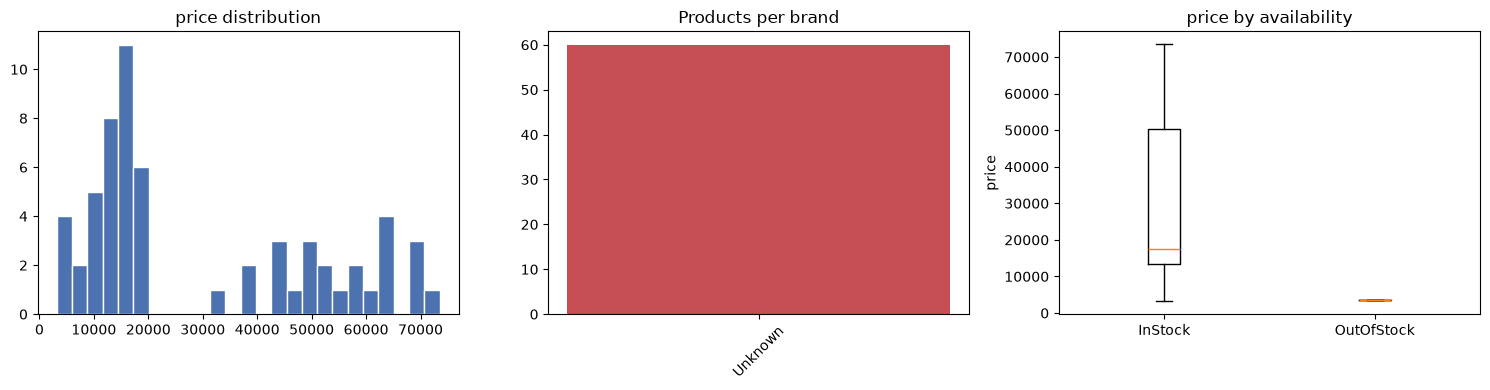

In [25]:
if eda_target is None:
    print("No numeric column to plot — EDA charts skipped")
else:
    fig, axes = plt.subplots(1, 3, figsize=(15, 4))

    axes[0].hist(df[eda_target].dropna(), bins=25, color="#4c72b0", edgecolor="white")
    axes[0].set_title(f"{eda_target} distribution")

    brand_counts = df["brand"].value_counts()
    axes[1].bar(brand_counts.index, brand_counts.values, color="#c44e52")
    axes[1].set_title("Products per brand")
    axes[1].tick_params(axis="x", rotation=45)

    groups = [(k, g[eda_target].dropna().values) for k, g in df.groupby("availability")]
    groups = [(k, v) for k, v in groups if len(v)]
    axes[2].boxplot([v for _, v in groups], tick_labels=[k for k, _ in groups])
    axes[2].set_title(f"{eda_target} by availability")
    axes[2].set_ylabel(eda_target)

    plt.tight_layout()
    plt.show()


## Cell 8 — Preprocessing + regression (declared target)

Predicts whatever `TARGETS["regression"]` declares in Cell 0 (price by
default). Numeric derived features + one-hot categoricals, then
LinearRegression vs RandomForestRegressor under 5-fold CV.

In [26]:
# regression on the target declared in Cell 0 (TARGETS["regression"],
# resolved against this dataset as REG_TARGET in the cleaning cell)
NUMERIC_FEATURES = [
    c for c in df.columns
    if pd.api.types.is_numeric_dtype(df[c]) and c != REG_TARGET
]
CATEGORICAL_FEATURES = [c for c in ("brand", "availability") if c in df.columns]

# numeric branch only when the data actually yields numeric features — some
# datasets have none (no derived numbers, no ratings)
_transformers = [
    ("cat", OneHotEncoder(handle_unknown="ignore"), CATEGORICAL_FEATURES),
]
if NUMERIC_FEATURES:
    _transformers.insert(0, (
        "num",
        Pipeline([
            ("impute", SimpleImputer(strategy=MINING_CONFIG["numeric_fill_strategy"])),
            ("scale", StandardScaler()),
        ]),
        NUMERIC_FEATURES,
    ))
preprocessor = ColumnTransformer(transformers=_transformers)

reg_model = None
model_df = df.dropna(subset=[REG_TARGET]) if REG_TARGET else df.copy()

# modelling needs a sane amount of data — tiny scrapes skip the regression
# entirely and let enrichment fall back to the median
MIN_ROWS_FOR_REGRESSION = 15

if not REG_TARGET:
    print(
        f"Regression target unusable (declared: {TARGETS.get('regression')!r}) "
        "— regression skipped. Missing values fall back to the median "
        "during enrichment."
    )
elif len(model_df) < MIN_ROWS_FOR_REGRESSION:
    print(
        f"Only {len(model_df)} rows for '{REG_TARGET}' (< {MIN_ROWS_FOR_REGRESSION}) "
        "— regression/imputation skipped. Missing values fall back to the "
        "median during enrichment."
    )
else:
    X = model_df[NUMERIC_FEATURES + CATEGORICAL_FEATURES]
    y = model_df[REG_TARGET]

    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, random_state=MINING_CONFIG["random_state"]
    )

    models = {
        "LinearRegression": LinearRegression(),
        "RandomForest": RandomForestRegressor(n_estimators=300, random_state=MINING_CONFIG["random_state"]),
    }

    results = {}
    for model_name, model in models.items():
        pipeline = Pipeline([("prep", preprocessor), ("model", model)])
        cv_r2 = cross_val_score(pipeline, X_train, y_train, cv=5, scoring="r2")
        pipeline.fit(X_train, y_train)
        y_pred = pipeline.predict(X_test)
        results[model_name] = {
            "cv_r2_mean": cv_r2.mean(),
            "test_r2": r2_score(y_test, y_pred),
            "test_mae": mean_absolute_error(y_test, y_pred),
        }
        print(f"{model_name:18s} CV R2 = {cv_r2.mean():.3f}  Test R2 = {results[model_name]['test_r2']:.3f}  MAE = {results[model_name]['test_mae']:,.2f}")

    best_name = max(results, key=lambda k: results[k]["test_r2"])
    print(f"\nBest '{REG_TARGET}' model: {best_name}")

    # refit on ALL rows -> this model also fills the target where it is missing
    reg_model = Pipeline([("prep", preprocessor), ("model", models[best_name])])
    reg_model.fit(X, y)


LinearRegression   CV R2 = -0.028  Test R2 = -408.746  MAE = 206,566.71


C:\Users\squal\AppData\Roaming\Python\Python312\site-packages\sklearn\impute\_base.py:647: UserWarning: Skipping features without any observed values: ['rating' 'power' 'battery']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
C:\Users\squal\AppData\Roaming\Python\Python312\site-packages\sklearn\impute\_base.py:647: UserWarning: Skipping features without any observed values: ['rating' 'power' 'battery']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
C:\Users\squal\AppData\Roaming\Python\Python312\site-packages\sklearn\impute\_base.py:647: UserWarning: Skipping features without any observed values: ['rating' 'battery']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
C:\Users\squal\AppData\Roaming\Python\Python312\site-packages\sklearn\impute\_base.py:647: UserWarning: Skipping features without any observed values: ['rating' 'battery']. A

RandomForest       CV R2 = 0.250  Test R2 = 0.649  MAE = 10,361.57

Best 'price' model: RandomForest


C:\Users\squal\AppData\Roaming\Python\Python312\site-packages\sklearn\impute\_base.py:647: UserWarning: Skipping features without any observed values: ['rating' 'battery']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
C:\Users\squal\AppData\Roaming\Python\Python312\site-packages\sklearn\impute\_base.py:647: UserWarning: Skipping features without any observed values: ['rating' 'battery']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(


## Cell 9 — Classification (target declared in Cell 0)

Classifies whatever `TARGETS["classification"]` declares. `"auto"` picks
the first derived boolean flag that shows two classes in the data; an
unusable target makes the section skip itself with a readable message.

C:\Users\squal\AppData\Roaming\Python\Python312\site-packages\sklearn\impute\_base.py:647: UserWarning: Skipping features without any observed values: ['rating' 'battery']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
C:\Users\squal\AppData\Roaming\Python\Python312\site-packages\sklearn\impute\_base.py:647: UserWarning: Skipping features without any observed values: ['rating' 'battery']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
C:\Users\squal\AppData\Roaming\Python\Python312\site-packages\sklearn\impute\_base.py:647: UserWarning: Skipping features without any observed values: ['rating' 'battery']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
C:\Users\squal\AppData\Roaming\Python\Python312\site-packages\sklearn\impute\_base.py:647: UserWarning: Skipping features without any observed values: ['rating' 'battery']. At least one non-

Classification target (declared): is_smart

=== LogisticRegression — accuracy: 0.967 ===
              precision    recall  f1-score   support

           0       0.97      1.00      0.98        29
           1       0.00      0.00      0.00         1

    accuracy                           0.97        30
   macro avg       0.48      0.50      0.49        30
weighted avg       0.93      0.97      0.95        30



C:\Users\squal\AppData\Roaming\Python\Python312\site-packages\sklearn\impute\_base.py:647: UserWarning: Skipping features without any observed values: ['rating' 'battery']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(



=== RandomForest — accuracy: 0.967 ===
              precision    recall  f1-score   support

           0       0.97      1.00      0.98        29
           1       0.00      0.00      0.00         1

    accuracy                           0.97        30
   macro avg       0.48      0.50      0.49        30
weighted avg       0.93      0.97      0.95        30

Best classifier: LogisticRegression


C:\Users\squal\AppData\Roaming\Python\Python312\site-packages\sklearn\impute\_base.py:647: UserWarning: Skipping features without any observed values: ['rating' 'battery']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
C:\Users\squal\AppData\Roaming\Python\Python312\site-packages\sklearn\impute\_base.py:647: UserWarning: Skipping features without any observed values: ['rating' 'battery']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
C:\Users\squal\AppData\Roaming\Python\Python312\site-packages\sklearn\impute\_base.py:647: UserWarning: Skipping features without any observed values: ['rating' 'battery']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
C:\Users\squal\AppData\Roaming\Python\Python312\site-packages\sklearn\impute\_base.py:647: UserWarning: Skipping features without any observed values: ['rating' 'battery']. At least one non-

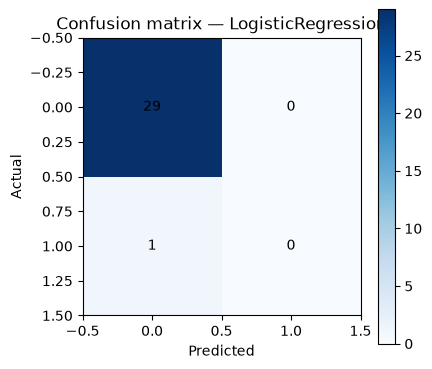

In [27]:
# target declared in Cell 0 (TARGETS["classification"], resolved against
# this dataset as CLF_TARGET in the cleaning cell — "auto" picks the first
# derived flag that actually shows two classes)
clf_target = CLF_TARGET

if clf_target is None:
    print(
        "Classification skipped — declared target "
        f"{TARGETS.get('classification')!r} is unusable for this dataset. "
        "Set TARGETS['classification'] in the declaration cell."
    )
else:
    print(f"Classification target (declared): {clf_target}")

    # features: everything numeric/categorical except the target itself
    clf_features = [
        c for c in dict.fromkeys(
            ["brand", "availability"]
            + ([REG_TARGET] if REG_TARGET else [])
            + NUMERIC_FEATURES
        )
        if c != clf_target
    ]

    usable = model_df[clf_target].notna()
    Xc = model_df.loc[usable, clf_features]
    yc_raw = model_df.loc[usable, clf_target]
    n_classes = int(yc_raw.nunique())
    min_class = int(yc_raw.value_counts().min()) if len(yc_raw) else 0

    if len(yc_raw) < 10 or n_classes < 2 or min_class < 2:
        print(
            f"'{clf_target}': {len(yc_raw)} rows / {n_classes} class(es), "
            f"smallest class = {min_class} — not enough data for "
            "classification, skipping"
        )
    elif n_classes > 20:
        print(
            f"'{clf_target}': {n_classes} distinct values look continuous — "
            "not a classification target, skipping (declare a boolean or "
            "low-cardinality column in TARGETS['classification'])"
        )
    else:
        # 0/1 ints for boolean/numeric targets, strings for text targets
        if pd.api.types.is_bool_dtype(yc_raw) or pd.api.types.is_numeric_dtype(yc_raw):
            yc = yc_raw.astype(int)
        else:
            yc = yc_raw.astype(str)

        # keep >= 1 sample of every class in both splits, even for rare classes
        test_size = 0.2 if min_class >= 10 else min(0.5, 2 / min_class)
        Xc_train, Xc_test, yc_train, yc_test = train_test_split(
            Xc, yc, test_size=test_size,
            random_state=MINING_CONFIG["random_state"], stratify=yc,
        )

        num_cols = [c for c in clf_features if pd.api.types.is_numeric_dtype(Xc[c])]
        cat_cols = [c for c in clf_features if c not in num_cols]
        clf_transformers = []
        if num_cols:
            clf_transformers.append((
                "num",
                Pipeline([
                    ("impute", SimpleImputer(strategy=MINING_CONFIG["numeric_fill_strategy"])),
                    ("scale", StandardScaler()),
                ]),
                num_cols,
            ))
        if cat_cols:
            clf_transformers.append(("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols))
        clf_preprocessor = ColumnTransformer(transformers=clf_transformers)

        classifiers = {
            "LogisticRegression": LogisticRegression(max_iter=1000),
            "RandomForest": RandomForestClassifier(n_estimators=300, random_state=MINING_CONFIG["random_state"]),
        }

        fitted_classifiers = {}
        for clf_name, clf in classifiers.items():
            clf_pipeline = Pipeline([("prep", clf_preprocessor), ("model", clf)])
            clf_pipeline.fit(Xc_train, yc_train)
            fitted_classifiers[clf_name] = clf_pipeline
            print(f"\n=== {clf_name} — accuracy: {accuracy_score(yc_test, clf_pipeline.predict(Xc_test)):.3f} ===")
            print(classification_report(yc_test, clf_pipeline.predict(Xc_test), zero_division=0))

        best_clf_name = max(
            fitted_classifiers,
            key=lambda n: accuracy_score(yc_test, fitted_classifiers[n].predict(Xc_test)),
        )
        print(f"Best classifier: {best_clf_name}")

        cm = confusion_matrix(yc_test, fitted_classifiers[best_clf_name].predict(Xc_test))
        fig, ax = plt.subplots(figsize=(4.5, 4))
        im = ax.imshow(cm, cmap="Blues")
        ax.set_title(f"Confusion matrix — {best_clf_name}")
        ax.set_xlabel("Predicted")
        ax.set_ylabel("Actual")
        for (i, j), value in np.ndenumerate(cm):
            ax.text(j, i, str(value), ha="center", va="center")
        plt.colorbar(im)
        plt.tight_layout()
        plt.show()


## Cell 10 — Clustering — market segments (elbow + K-Means)

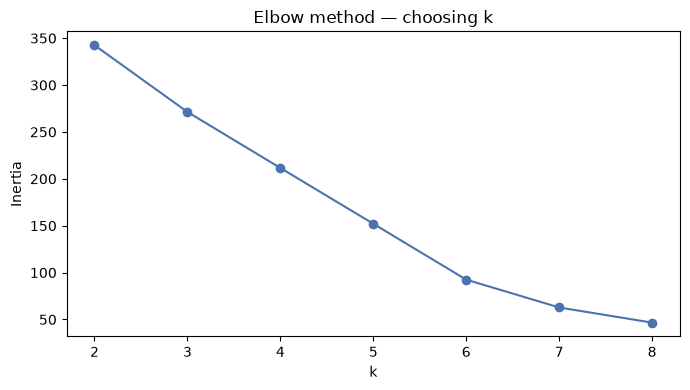

K-Means on columns: ['price', 'rating_count', 'size', 'capacity', 'power', 'storage', 'is_smart', 'is_wireless', 'is_inverter', 'is_hd', 'is_rechargeable', 'is_refurbished', 'is_bundle'] (k=3)
Cluster profiles (means):
            price  rating_count     size  capacity   power  storage  is_smart  \
segment                                                                         
0        17833.05           0.0   496.21    207.27  2990.0     1.75      0.05   
1        61000.00           0.0     3.50       NaN     NaN    44.00      0.00   
2        57374.38           0.0  1109.31    700.00     NaN     2.00      0.00   

         is_wireless  is_inverter  is_hd  is_rechargeable  is_refurbished  \
segment                                                                     
0                0.0          0.0   0.00              0.0             0.0   
1                0.0          0.0   0.00              0.0             0.0   
2                0.0          0.0   0.06              0.0          

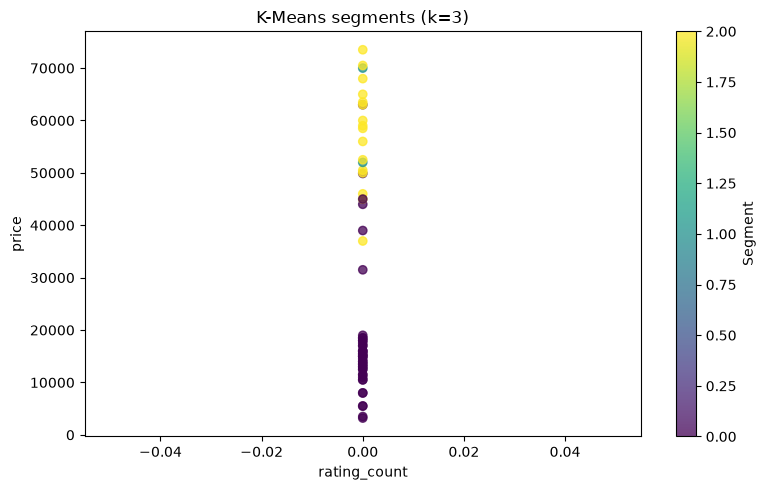

In [28]:
# cluster on the declared target + every numeric feature (deduped)
cluster_cols = list(dict.fromkeys(([REG_TARGET] if REG_TARGET else []) + NUMERIC_FEATURES))

# numeric coercion + drop derived features that never matched on this data
# (a vague pattern that matched nothing -> all-NaN column, useless for k-means)
X_cl = model_df[cluster_cols].apply(pd.to_numeric, errors="coerce")
X_cl = X_cl.dropna(axis=1, how="all")

if X_cl.shape[1] < 2 or X_cl.shape[0] < 4:
    print("Not enough usable numeric data for clustering — skipped")
else:
    imputer = SimpleImputer(strategy=MINING_CONFIG["numeric_fill_strategy"])
    X_imp = imputer.fit_transform(X_cl)

    X_scaled = StandardScaler().fit_transform(X_imp)

    inertias = []
    # k must never exceed the sample count (tiny datasets)
    k_range = range(2, min(8, X_cl.shape[0]) + 1)

    for k in k_range:
        km = KMeans(n_clusters=k, random_state=MINING_CONFIG["random_state"], n_init=10)
        km.fit(X_scaled)
        inertias.append(km.inertia_)

    plt.figure(figsize=(7, 4))
    plt.plot(list(k_range), inertias, marker="o", color="#4c72b0")
    plt.title("Elbow method — choosing k")
    plt.xlabel("k")
    plt.ylabel("Inertia")
    plt.tight_layout()
    plt.show()

    K_BEST = max(2, min(MINING_CONFIG["kmeans_k"], len(k_range)))

    kmeans = KMeans(n_clusters=K_BEST, random_state=MINING_CONFIG["random_state"], n_init=10)
    model_df = model_df.copy()
    model_df["segment"] = kmeans.fit_predict(X_scaled)

    profile = (
        model_df.groupby("segment")[list(X_cl.columns)]
        .mean()
        .round(2)
    )
    profile["count"] = model_df["segment"].value_counts().sort_index()
    print(f"K-Means on columns: {list(X_cl.columns)} (k={K_BEST})")
    print("Cluster profiles (means):")
    print(profile)

    # axis labels follow the declared target, whatever it is
    y_col = REG_TARGET if REG_TARGET in X_cl.columns else X_cl.columns[0]
    plot_col = next(
        (col for col in X_cl.columns if col != y_col and model_df[col].notna().any()),
        y_col,
    )

    fig, ax = plt.subplots(figsize=(8, 5))
    scatter = ax.scatter(
        model_df[plot_col],
        model_df[y_col],
        c=model_df["segment"],
        cmap="viridis",
        alpha=0.75,
    )
    ax.set_xlabel(plot_col)
    ax.set_ylabel(y_col)
    ax.set_title(f"K-Means segments (k={K_BEST})")
    plt.colorbar(scatter, label="Segment")
    plt.tight_layout()
    plt.show()


## Cell 11 — Attach mined values back onto the raw records

The backend no longer receives raw scrapes: each record gets
`mined` — imputed price where missing, the generic derived features,
and its cluster segment. Mined values are marked with `_mined: true`
so the backend/front-end can tell them from scraped facts.

In [29]:
# price imputation for records that were missing it — the regression model
# is only a *price* imputer when the declared target is price; otherwise
# (and when the model was skipped) fall back to the observed median
unpriced = df[df["price"].isna()]
imputed_count = 0
can_impute = REG_TARGET == "price" and reg_model is not None

if len(unpriced) and can_impute:
    imputed_prices = reg_model.predict(unpriced[NUMERIC_FEATURES + CATEGORICAL_FEATURES])
    df.loc[unpriced.index, "price_imputed"] = np.round(imputed_prices, -2)
    imputed_count = int(df["price_imputed"].notna().sum())
elif len(unpriced):
    # regression skipped (tiny dataset / non-price target): observed median,
    # or 0 when no priced rows exist at all
    fallback = float(df["price"].median())
    df.loc[unpriced.index, "price_imputed"] = 0.0 if np.isnan(fallback) else round(fallback, -2)
    imputed_count = int(len(unpriced))
else:
    df["price_imputed"] = np.nan

df["price_imputed"] = df["price_imputed"].fillna(0).astype(float)

# map segment back onto every record row by slug (absent when clustering
# was skipped for a tiny dataset)
if "segment" in model_df.columns:
    segment_by_slug = model_df.set_index("productSlug")["segment"].to_dict()
    df["segment"] = df["productSlug"].map(segment_by_slug).astype("float")
else:
    df["segment"] = np.nan

print(f"Records enriched. Price imputations: {imputed_count}, records with segment: {int(df['segment'].notna().sum())}")

if not df.empty:
    preview_cols = list(dict.fromkeys(
        c for c in ("name", REG_TARGET, "price_imputed", "segment") if c
    ))
    df[preview_cols].head()


Records enriched. Price imputations: 0, records with segment: 60


## Cell 12 — Export the mined dataset to CSV

Before anything is sent to the backend, the enriched frame is flattened
(dict/list columns become JSON strings) and written to a local CSV. Location
and filename come from `CSV_EXPORT` in the declaration cell, so every run
leaves a reusable dataset — even if the upload step is interrupted.


In [30]:
# Flatten structured columns so they survive the CSV round-trip, then write
# the file configured by CSV_EXPORT in the declaration cell.
if CSV_EXPORT.get("enabled", True):
    csv_export_df = df.copy()

    for col in ("specifications", "images"):
        if col in csv_export_df.columns:
            csv_export_df[col] = csv_export_df[col].apply(
                lambda v: json.dumps(v, ensure_ascii=False) if isinstance(v, (dict, list)) else v
            )

    if CSV_EXPORT.get("stamp_rows", True):
        csv_export_df["exported_at"] = pd.Timestamp.now().isoformat(timespec="seconds")
        csv_export_df["site"] = ACTIVE_SITE

    export_dir = Path(CSV_EXPORT["output_dir"]).expanduser()
    export_dir.mkdir(parents=True, exist_ok=True)
    csv_path = export_dir / CSV_EXPORT["filename"].format(
        site=ACTIVE_SITE,
        date=pd.Timestamp.now().strftime("%Y%m%d"),
        timestamp=pd.Timestamp.now().strftime("%Y%m%d-%H%M%S"),
    )
    csv_export_df.to_csv(csv_path, index=False, encoding="utf-8-sig")

    print(f"CSV exported: {csv_path.resolve()}  ({len(csv_export_df)} rows, {len(csv_export_df.columns)} cols)")
    print("Columns:", ", ".join(map(str, csv_export_df.columns)))
else:
    print("CSV export disabled in the declaration cell (CSV_EXPORT)")


CSV exported: E:\Code\data_mining_python\app\data\startech_products_20260927-232645.csv  (60 rows, 31 cols)
Columns: name, productSlug, price, image, url, availability, specifications, external_id, sku, description, short_description, images, rating, rating_count, size, capacity, power, storage, battery, is_smart, is_wireless, is_inverter, is_hd, is_rechargeable, is_refurbished, is_bundle, brand, price_imputed, segment, exported_at, site


## Cell 13 — Config-driven backend mapping + send

`FIELD_MAP` decides how a record becomes the backend Product schema —
change it here, not in the send logic. Mined fields ride along in
`attributes` / `specifications` and are flagged `_mined`.

In [31]:
def is_retryable_error(exc):
    """Retry only transient failures: 5xx, 429, network errors."""

    if isinstance(exc, httpx.HTTPStatusError):
        status = exc.response.status_code if exc.response is not None else 0
        return status >= 500 or status == 429

    return isinstance(exc, httpx.HTTPError)


def _clean_nan(value):
    """NaN -> None everywhere, so the payload is always valid JSON
    (json.dumps would emit bare NaN, which Express/body-parser rejects)."""
    if isinstance(value, float) and pd.isna(value):
        return None
    if isinstance(value, dict):
        return {k: _clean_nan(v) for k, v in value.items()}
    if isinstance(value, list):
        return [_clean_nan(v) for v in value]
    return value


def record_to_payload(record):
    payload = {}
    for backend_field, source in FIELD_MAP.items():
        payload[backend_field] = source(record) if callable(source) else record.get(source)
    payload["sku"] = str(record.get("sku") or "")
    payload["barcode"] = ""
    payload["mpn"] = ""
    payload["gtin"] = ""
    return _clean_nan(payload)


@retry(
    stop=stop_after_attempt(3),
    wait=wait_exponential(multiplier=1, min=1, max=10),
    retry=retry_if_exception(is_retryable_error),
    reraise=True,
)
async def send_product_to_backend(record, http_client):
    payload = record_to_payload(record)
    response = await http_client.post(PRODUCT_ENDPOINT, json=payload)
    response.raise_for_status()
    return response.json()


async def product_exists(http_client, product_slug):
    try:
        response = await http_client.get(f"{PRODUCT_ENDPOINT}/slug/{product_slug}")
        return response.status_code == 200
    except httpx.HTTPStatusError as exc:
        if exc.response is not None and exc.response.status_code == 404:
            return False
        raise


async def send_all_products_to_backend(records_df, http_client):
    sent, skipped, failed = [], [], []
    total = len(records_df)

    for i, row in enumerate(records_df.to_dict("records"), start=1):
        product_slug = row["productSlug"]
        label = f"[{i}/{total}]"

        try:
            if await product_exists(http_client, product_slug):
                skipped.append(row["name"])
                print(f"{label} SKIPPED (already in backend): {row['name']}")
                continue

            await send_product_to_backend(row, http_client)
            sent.append(row["name"])
            print(f"{label} OK: {row['name']}")

        except httpx.HTTPStatusError as exc:
            status = exc.response.status_code if exc.response is not None else None
            if status == 409:
                skipped.append(row["name"])
                print(f"{label} SKIPPED (duplicate): {row['name']}")
            else:
                # surface the backend's own message (Joi / AppError) if it sent one
                try:
                    reason = exc.response.json().get("message")
                except Exception:
                    reason = None
                detail = f"{status}: {reason}" if reason else repr(exc)
                failed.append((row["name"], detail))
                print(f"{label} FAILED: {row['name']} — {detail}")
        except httpx.HTTPError as exc:
            failed.append((row["name"], repr(exc)))
            print(f"{label} FAILED: {row['name']} — {exc!r}")

    return sent, skipped, failed


print(f"Sender ready for site '{SITE['name']}' — FIELD_MAP fields: {list(FIELD_MAP)}")

Sender ready for site 'startech' — FIELD_MAP fields: ['name', 'productSlug', 'price', 'currency', 'description', 'shortDescription', 'images', 'rating', 'specifications', 'attributes', 'tags', 'sources', 'status']


## Cell 14 — Send mined records to the backend

In [32]:
sent, skipped, failed = await send_all_products_to_backend(df, http_client)

print()
print(f"Sent: {len(sent)}, Skipped: {len(skipped)}, Failed: {len(failed)}")

if failed:
    print("Failed products:")
    for name, err in failed:
        print(f"  - {name}: {err}")

await http_client.close()

[1/60] FAILED: DateUp 8 Port PDU for Server Rack — ConnectError('All connection attempts failed')
[2/60] FAILED: DateUp 8 Port PDU With 2 Meter Cable for Server Rack — ConnectError('All connection attempts failed')
[3/60] FAILED: COTE CPDU-1U-6US-13AMP 6-Port Universal 3 Pin PDU — ConnectError('All connection attempts failed')
[4/60] FAILED: COTE CPDU-1U-6C13-13AMP 6 Port C13 PDU — ConnectError('All connection attempts failed')
[5/60] FAILED: COTE CPDU-1U-10C13-13AMP 10 Port Back-to-Back PDU — ConnectError('All connection attempts failed')
[6/60] FAILED: COTE CPDU-1U-12(8-C13+4-C19)-16AMP 1U 12 Port Back-to-Back PDU — ConnectError('All connection attempts failed')
[7/60] FAILED: Solitine SOL-265-6U 6U Server Rack — ConnectError('All connection attempts failed')
[8/60] FAILED: Nexakey NX-9U Wall Mount Server Rack — ConnectError('All connection attempts failed')
[9/60] FAILED: Solitine SOL-265-9U 9U Server Rack — ConnectError('All connection attempts failed')
[10/60] FAILED: DATEUP 6U Se

## Course learning outcomes — now site-agnostic

| Stage | Where it lives | Technique |
|---|---|---|
| Site declaration | Cell 0 | selectors, normalizers, generic derive patterns + declared targets |
| Data collection | Cells 2–3 | generic profile-driven async scraper |
| Detail pages | Cell 4 | follow each product's URL/slug, merge its full data |
| JSON-in-HTML channel | Cell 2 | embedded `__NEXT_DATA__` extraction for JS-rendered sites |
| Cleaning | Cell 6 | config-driven dedup, winsorization, label canonicalization |
| Robustness | all | fail-fast on zero-match scrapes; tiny datasets skip modelling gracefully instead of crashing |
| EDA | Cell 7 | distributions, frequencies, boxplots |
| Regression / imputation | Cell 8 | CV model comparison on the declared target, reused as price imputer |
| Classification | Cell 9 | declared target (auto = first usable derived flag), guarded when absent |
| Clustering | Cell 10 | elbow + K-Means segments |
| Enrichment | Cell 11 | mined values attached to raw records |
| CSV export | Cell 12 | flattened mined dataset saved locally before upload, path in the declaration |
| Backend mapping | Cell 13 | `FIELD_MAP` — schema mapping without touching send logic |
| Sending | Cell 14 | skip-if-exists, 409-tolerant, transient-only retries |

**Pipeline:** any site → one profile → scrape → detail → mine → enrich → backend.